In [ ]:
! pip install langchain langchain-openai langchain-community langgraph python-dotenv faiss-cpu pypdf

In [7]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

In [ ]:
load_dotenv()

In [ ]:
llm = ChatOpenAI(model='gpt-4o-mini')

In [8]:
loader = PyPDFLoader('intro-to-ml.pdf')
docs = loader.load()

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/BKSOJN+MinionPro-SemiboldIt', '/Encoding': {'/Differences': [128, '/udieresis'], '/Type': '/Encoding'}, '/FirstChar': 32, '/FontDescriptor': IndirectObject(6, 0, 4489188640), '/LastChar': 128, '/Subtype': '/Type1', '/ToUnicode': IndirectObject(8, 0, 4489188640), '/Type': '/Font', '/Widths': [223, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 253, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 669, 0, 645, 724, 0, 0, 692, 0, 0, 0, 0, 0, 882, 0, 0, 0, 0, 0, 482, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 509, 0, 392, 525, 412, 286, 0, 526, 287, 0, 0, 265, 0, 543, 484, 0, 0, 381, 348, 316, 541, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 541]}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/BKSNZS+MyriadPro-SemiboldCond', '/Encoding': {'/Differences': [128, '/

In [9]:
len(docs)

392

In [10]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [ ]:
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')
vector_store = FAISS.from_documents(chunks, embeddings)

In [ ]:
vector_store

In [ ]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k': 4})

In [11]:
# one way to use RAG in langchain is to define it as a tool
@tool
def rag_tool(query):
    """
    Retrieve relevant information from the pdf document.
    Use this tool when the user asks factual / conceptual questions
    that might be answered from the stored documents.
    """
    result = retriever.invoke(query)
    
    context =[doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]
    
    return{
        'query': query,
        'context': context,
        'metadata': metadata
    }

In [ ]:
tools = [rag_tool]
llm_with_tool = llm.bind_tools(tools)

In [13]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [14]:
def chat_node(state: ChatState):
    messages = state['messages']
    response = llm_with_tool.invoke(messages)
    
    return {'messages': [response]}

In [15]:
tool_node = ToolNode(tools)

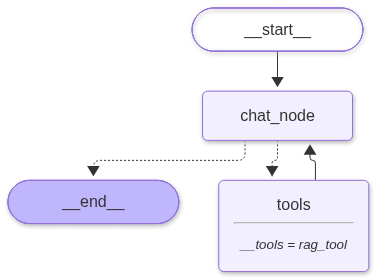

In [ ]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()
chatbot

In [ ]:
result = chatbot.invoke{
    'messages': [
        HumanMessage(
            content=('Using the pdf notes, explain how to find the ideal value of K in KNN')
        )
    ]
}

In [ ]:
print(result['messages'][-1].content)